# Frame First: what the Combine can and cannot tell you about a receiver's separation

**NFL Big Data Bowl 2027, Open Track.** This notebook reproduces every number and figure in the write-up from the raw competition files. It runs top to bottom on a CPU session in a few minutes and uses no external data.

The question is narrow on purpose. For wide receivers, which Combine measurements say anything about how open a rookie gets on Sundays, and does the 10 Hz Combine tracking add to them?

What the cells below show, in order:

1. Separation at the throw is a stable receiver trait once every route is counted, not only targets.
2. Weight and height predict it in a draft class the model never saw. The official 40 time and draft slot do not.
3. Tracked top speed adds almost nothing to that prediction, and position-drill tracking makes it worse, because single drill reps repeat poorly.
4. Size costs the most separation on screens and crossing routes, and against zone coverage.
5. Game tracking shows why. On the same route with the same time to throw, lighter receivers reach a higher speed before the ball comes out. That play speed is where tracked Combine speed does help.
6. In season, frame forecasts a receiver's later separation better than his own first routes of NFL tape.

Every statistic is printed by the cell that computes it. The write-up quotes those printed values.

## 1. Helpers

Five small functions do the measurement and the validation. They are defined first so that the repository's tests can run this exact cell against synthetic inputs: ball rows and repeated attempts must not register as braking, play speed must ignore pre-snap motion and running after the throw, and a held-out draft class must never influence its own predictions.

In [1]:
# helpers
import numpy as np
import pandas as pd
import polars as pl
import statsmodels.formula.api as smf


def split_half_reliability(reps, value, splits, seed):
    """Mean correlation between receiver averages computed on random halves of their reps."""
    rng = np.random.default_rng(seed)
    correlations = []
    for _ in range(splits):
        halves = reps.assign(half=rng.integers(0, 2, len(reps))).groupby(["nfl_id", "half"])[value].mean().unstack()
        correlations.append(halves[0].corr(halves[1]))
    return float(np.mean(correlations))


def leave_one_class_out(players, features, target):
    """Predict each draft class with an OLS model fitted only on the other classes."""
    predicted = np.zeros(len(players))
    for year in players["draft_year"].unique():
        held_out = (players["draft_year"] == year).to_numpy()
        predicted[held_out] = smf.ols(f"{target} ~ {features}", players[~held_out]).fit().predict(players[held_out])
    return predicted


def context_residual(reps, target, context):
    """What is left of a rep-level outcome after an OLS fit on its playing context."""
    return smf.ols(f"{target} ~ {context}", reps).fit().resid


MIN_REP_FRAMES = 15
DRILL_METRICS = ["brake", "accel", "speed"]


def drill_reps(tracking):
    """One row per position-drill rep: peak braking, peak re-acceleration and top speed.

    Player rows only and one series per rep, because 2025 skill drills also carry ball rows under the
    receiver's id. Speed is smoothed over three frames before it is differenced. Each metric is then
    standardized within drill and draft class so that drills of different difficulty can be averaged.
    """
    frames = tracking.filter(pl.col("entity_type") == "PLAYER").sort(["event_id", "time"])
    frames = frames.with_columns(pl.col("s").rolling_mean(3, center=True).over("event_id").alias("smooth"))
    frames = frames.with_columns(
        ((pl.col("smooth").shift(-1).over("event_id") - pl.col("smooth").shift(1).over("event_id")) / 0.2).alias("ds")
    )
    reps = (
        frames.group_by(["nfl_id", "event_id", "draft_year", "drill_name"])
        .agg(
            (-pl.col("ds").min()).alias("brake"),
            pl.col("ds").max().alias("accel"),
            pl.col("s").max().alias("speed"),
            pl.len().alias("frames"),
        )
        .filter(pl.col("frames") >= MIN_REP_FRAMES)
    )
    group = ["drill_name", "draft_year"]
    return reps.with_columns(
        [((pl.col(m) - pl.col(m).mean().over(group)) / pl.col(m).std().over(group)).alias(m + "_z") for m in DRILL_METRICS]
    ).sort("event_id")


def play_speed(tracking):
    """Peak speed between the snap and the throw, and the time between them, for each tracked rep."""
    rep = ["game_id", "play_id", "nfl_id"]
    snap = tracking.filter(pl.col("event") == "ball_snap").group_by(rep).agg(pl.col("time").min().alias("snap"))
    throw = tracking.filter(pl.col("event") == "pass_forward").group_by(rep).agg(pl.col("time").min().alias("throw"))
    window = tracking.join(snap, on=rep).join(throw, on=rep).filter(pl.col("time").is_between(pl.col("snap"), pl.col("throw")))
    return (
        window.group_by(rep)
        .agg(
            pl.col("s").max().alias("peak_speed"),
            ((pl.col("throw").first() - pl.col("snap").first()).dt.total_milliseconds() / 1000).alias("time_to_throw"),
        )
        .sort(rep)
    )

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib import animation
from scipy import stats
from sklearn.metrics import r2_score

# Kaggle has mounted competition data at more than one path; find the files instead of assuming one.
KAGGLE_INPUT = Path("/kaggle/input")
DATA_DIR = next(KAGGLE_INPUT.rglob("players.csv")).parent if KAGGLE_INPUT.exists() else Path("data/raw")
SEASONS = (2023, 2024, 2025)
MIN_ROUTES = 100
UNDRAFTED_PICK = 300
SEED = 0
FRAME = "combine_weight + combine_height"
CONTEXT = "C(route_ran) + C(lined_up_position) + C(team_coverage_man_zone) + C(season)"
REP = ["game_id", "play_id", "nfl_id"]
VERTICAL_ROUTES = ["GO", "POST", "CORNER"]

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK_SECONDARY, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "figure.dpi": 110,
        "font.family": "sans-serif",
        "font.size": 11,
        "text.color": INK,
        "axes.edgecolor": AXIS,
        "axes.labelcolor": INK_SECONDARY,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "xtick.labelcolor": INK_SECONDARY,
        "ytick.labelcolor": INK_SECONDARY,
        "legend.frameon": False,
    }
)


def headline(ax, title, subtitle):
    """Left-aligned finding as the title, with the sample underneath it."""
    ax.set_title(title, loc="left", fontsize=13, fontweight="bold", pad=24)
    ax.text(0, 1.02, subtitle, transform=ax.transAxes, fontsize=10, color=INK_SECONDARY, va="bottom")


players = pl.read_csv(DATA_DIR / "players.csv", null_values=["NA"])
combine = pl.read_csv(DATA_DIR / "combine_results.csv", null_values=["NA"])
games = pl.read_csv(DATA_DIR / "games.csv")
combine_tracking = pl.read_csv(DATA_DIR / "combine_tracking.csv")
text_columns = ["pressure_allowed", "quick_pressure", "unblocked_pressure", "lined_up_position", "blitzing", "target", "in_motion_at_ball_snap"]
plays = (
    pl.read_csv(
        DATA_DIR / "player_play.csv",
        null_values=["NA", ""],
        infer_schema_length=100_000,
        schema_overrides={c: pl.Utf8 for c in text_columns} | {c: pl.Float64 for c in ["sack", "sack_allowed", "extended_sack_allowed"]},
    )
    .join(games.select(["game_id", "season", "season_type"]), on="game_id")
    .filter(pl.col("season_type") == "REG")
    .join(players.select(["nfl_id", "nfl_position", "draft_year"]), on="nfl_id")
)

top_speed = (
    combine_tracking.filter((pl.col("entity_type") == "PLAYER") & (pl.col("drill_type") == "FORTY_YARD_DASH"))
    .group_by("nfl_id")
    .agg(pl.col("s").max().alias("top_speed"))
)
prospects = (
    players.select(["nfl_id", "display_name", "draft_overall_pick"])
    .join(combine.select(["nfl_id", "combine_weight", "combine_height", "forty"]), on="nfl_id")
    .join(top_speed, on="nfl_id", how="left")
    .with_columns(pl.col("draft_overall_pick").fill_null(UNDRAFTED_PICK).log().alias("log_pick"))
    .to_pandas()
)
print(f"Data from {DATA_DIR}")
print(f"{len(players)} prospects | {plays.height:,} regular-season player-plays | {combine_tracking.height:,} Combine tracking rows")

Data from data/raw
510 prospects | 249,269 regular-season player-plays | 463,189 Combine tracking rows


## 2. The outcome: separation on every route

`player_play.csv` records the distance to the nearest defender at the throw for every route a receiver runs, not only when he is targeted. Using every route gives several times more reps per receiver.

Raw separation depends on the job a receiver is given, so each rep is also compared with the average for the same route, alignment, coverage type and season. The receiver's mean of those differences is his role-adjusted separation. Receivers need at least 100 regular-season routes to enter the cohort.

In [3]:
routes = plays.filter(
    (pl.col("nfl_position") == "WR") & pl.col("route_ran").is_not_null() & pl.col("separation_at_pass_forward").is_not_null()
).select(
    REP
    + ["season", "draft_year", "route_ran", "lined_up_position", "cushion", "target"]
    + [pl.col("team_coverage_man_zone").fill_null("UNKNOWN"), pl.col("separation_at_pass_forward").alias("separation")]
).to_pandas()
routes["separation_adj"] = context_residual(routes, "separation", CONTEXT)

receivers = (
    routes.groupby(["nfl_id", "draft_year"], as_index=False)
    .agg(
        routes=("separation", "size"),
        separation=("separation", "mean"),
        separation_adj=("separation_adj", "mean"),
        vertical_share=("route_ran", lambda route: route.isin(VERTICAL_ROUTES).mean()),
    )
    .query("routes >= @MIN_ROUTES")
    .merge(prospects, on="nfl_id")
    .reset_index(drop=True)
)
cohort_routes = routes[routes["nfl_id"].isin(receivers["nfl_id"])]

print(f"Route reps with a recorded separation: {len(routes):,} by {routes['nfl_id'].nunique()} receivers, of which {int((routes['target'] == 'TRUE').sum()):,} were targets")
print(f"Receivers with at least {MIN_ROUTES} routes: {len(receivers)} | by draft class: {receivers['draft_year'].value_counts().sort_index().to_dict()} | median routes: {receivers['routes'].median():.0f}")
for column, label in [("separation", "raw separation"), ("separation_adj", "role-adjusted separation")]:
    r = split_half_reliability(cohort_routes, column, splits=200, seed=SEED)
    print(f"Split-half reliability of {label}: r = {r:.2f} (Spearman-Brown {2 * r / (1 + r):.2f})")
print(f"Spread across receivers: SD of raw separation {receivers['separation'].std():.2f} yd, of role-adjusted separation {receivers['separation_adj'].std():.2f} yd")

Route reps with a recorded separation: 30,566 by 82 receivers, of which 6,433 were targets
Receivers with at least 100 routes: 62 | by draft class: {2023: 28, 2024: 19, 2025: 15} | median routes: 354


Split-half reliability of raw separation: r = 0.84 (Spearman-Brown 0.91)


Split-half reliability of role-adjusted separation: r = 0.69 (Spearman-Brown 0.82)
Spread across receivers: SD of raw separation 0.40 yd, of role-adjusted separation 0.26 yd


## 3. Frame predicts separation

Frame means two Combine measurements taken with a scale and a tape: weight and height. The model is ordinary least squares. To test it on new players, it is fitted on two draft classes and scored on the third, for each class in turn.

combine_weight vs separation: r = -0.57 (p = 1.1e-06, n = 62)
combine_weight vs separation_adj: r = -0.60 (p = 2.7e-07, n = 62)
combine_height vs separation: r = -0.56 (p = 2.3e-06, n = 62)
combine_height vs separation_adj: r = -0.53 (p = 8.1e-06, n = 62)
In-sample fit: R2 = 0.37 | -0.079 yd per 10 lb at fixed height | -0.020 yd per inch at fixed weight
Weight and height correlate at r = 0.77



Leave-one-draft-class-out, frame only, all 62 receivers:
  out-of-class R2 = 0.338 (95% bootstrap interval 0.07 to 0.48), r = 0.58
  permutation p = 0.001 (1,000 shuffles)
  class 2023 predicted from the other two: r = 0.61 (n = 28)
  class 2024 predicted from the other two: r = 0.45 (n = 19)
  class 2025 predicted from the other two: r = 0.72 (n = 15)

Robustness of the frame result (leave-one-draft-class-out R2 | weight r):
                                                    sample  receivers  out_of_class_r2  weight_r  height_r
             at least 100 routes, role-adjusted (headline)         62             0.34     -0.60     -0.53
                       at least 100 routes, raw separation         62             0.34     -0.57     -0.56
                         at least 50 routes, role-adjusted         68             0.24     -0.56     -0.49
                        at least 150 routes, role-adjusted         56             0.36     -0.61     -0.54
                        at least 2

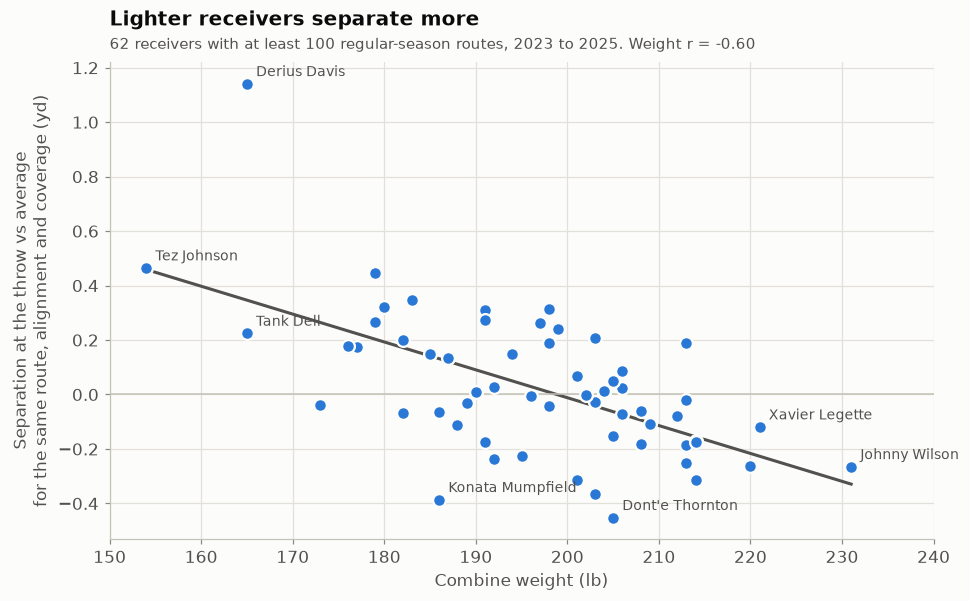

In [4]:
rng = np.random.default_rng(SEED)
for column in ["combine_weight", "combine_height"]:
    for outcome in ["separation", "separation_adj"]:
        r, p = stats.pearsonr(receivers[column], receivers[outcome])
        print(f"{column} vs {outcome}: r = {r:+.2f} (p = {p:.1e}, n = {len(receivers)})")

fit = smf.ols(f"separation_adj ~ {FRAME}", receivers).fit()
print(f"In-sample fit: R2 = {fit.rsquared:.2f} | {10 * fit.params['combine_weight']:+.3f} yd per 10 lb at fixed height | {fit.params['combine_height']:+.3f} yd per inch at fixed weight")
print(f"Weight and height correlate at r = {receivers['combine_weight'].corr(receivers['combine_height']):.2f}")

receivers["expected"] = leave_one_class_out(receivers, FRAME, "separation_adj")
frame_r2 = r2_score(receivers["separation_adj"], receivers["expected"])
draws = rng.integers(0, len(receivers), (2000, len(receivers)))
boot = [r2_score(receivers["separation_adj"].to_numpy()[i], receivers["expected"].to_numpy()[i]) for i in draws]
shuffled = receivers.copy()
null = []
for _ in range(1000):
    shuffled["separation_adj"] = rng.permutation(receivers["separation_adj"].to_numpy())
    null.append(r2_score(shuffled["separation_adj"], leave_one_class_out(shuffled, FRAME, "separation_adj")))
print(f"\nLeave-one-draft-class-out, frame only, all {len(receivers)} receivers:")
print(f"  out-of-class R2 = {frame_r2:.3f} (95% bootstrap interval {np.percentile(boot, 2.5):.2f} to {np.percentile(boot, 97.5):.2f}), r = {receivers['expected'].corr(receivers['separation_adj']):.2f}")
print(f"  permutation p = {(np.sum(np.array(null) >= frame_r2) + 1) / (len(null) + 1):.3f} (1,000 shuffles)")
for year, group in receivers.groupby("draft_year"):
    print(f"  class {year} predicted from the other two: r = {group['expected'].corr(group['separation_adj']):.2f} (n = {len(group)})")

print("\nRobustness of the frame result (leave-one-draft-class-out R2 | weight r):")
variants = {f"at least {MIN_ROUTES} routes, role-adjusted (headline)": receivers.assign(y=receivers["separation_adj"])}
variants[f"at least {MIN_ROUTES} routes, raw separation"] = receivers.assign(y=receivers["separation"])
for minimum in (50, 150, 200):
    table = routes.groupby(["nfl_id", "draft_year"], as_index=False).agg(routes=("separation", "size"), y=("separation_adj", "mean"))
    variants[f"at least {minimum} routes, role-adjusted"] = table[table["routes"] >= minimum].merge(prospects, on="nfl_id")
rookie = routes[routes["season"] == routes["draft_year"]].groupby(["nfl_id", "draft_year"], as_index=False).agg(routes=("separation", "size"), y=("separation_adj", "mean"))
variants[f"rookie season only, at least {MIN_ROUTES} routes"] = rookie[rookie["routes"] >= MIN_ROUTES].merge(prospects, on="nfl_id")
outlier = (receivers["separation_adj"] - fit.fittedvalues).abs().idxmax()
variants[f"headline sample without its largest outlier ({receivers.loc[outlier, 'display_name']})"] = receivers.drop(outlier).assign(y=lambda d: d["separation_adj"])
robustness = pd.DataFrame(
    [
        {
            "sample": label,
            "receivers": len(table),
            "out_of_class_r2": r2_score(table["y"], leave_one_class_out(table, FRAME, "y")),
            "weight_r": table["combine_weight"].corr(table["y"]),
            "height_r": table["combine_height"].corr(table["y"]),
        }
        for label, table in variants.items()
    ]
)
print(robustness.round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 5.6))
ax.scatter(receivers["combine_weight"], receivers["separation_adj"], s=70, color=BLUE, edgecolor=SURFACE, linewidth=1.5, zorder=3)
grid = np.linspace(receivers["combine_weight"].min(), receivers["combine_weight"].max(), 50)
slope, intercept = np.polyfit(receivers["combine_weight"], receivers["separation_adj"], 1)
ax.plot(grid, intercept + slope * grid, color=INK_SECONDARY, linewidth=2, zorder=2)
ax.axhline(0, color=AXIS, linewidth=1)
ranked = receivers.sort_values("separation_adj")
labelled = pd.concat([ranked.head(2), ranked.tail(2), receivers.nsmallest(2, "combine_weight"), receivers.nlargest(2, "combine_weight")]).drop_duplicates("nfl_id")
for row in labelled.itertuples():
    ax.annotate(row.display_name, (row.combine_weight, row.separation_adj), xytext=(6, 5), textcoords="offset points", fontsize=9, color=INK_SECONDARY)
ax.set_xlim(150, 240)
ax.set_xlabel("Combine weight (lb)")
ax.set_ylabel("Separation at the throw vs average\nfor the same route, alignment and coverage (yd)")
headline(ax, "Lighter receivers separate more", f"{len(receivers)} receivers with at least {MIN_ROUTES} regular-season routes, 2023 to 2025. Weight r = {receivers['combine_weight'].corr(receivers['separation_adj']):.2f}")
fig.tight_layout()
fig.savefig("fig1_frame_vs_separation.png", dpi=160)
plt.show()

## 4. What the stopwatch and the sensors add

Each row of the ladder is a different set of Combine information, scored the same way on the same receivers.

Tracking features follow common practice. Top speed is the fastest tracked frame of the 40-yard dash. For the position drills, speed is smoothed over three frames and differenced to get signed acceleration, the peak braking, peak re-acceleration and top speed of each rep are standardized within drill and draft class, and a prospect's reps are averaged. Ball rows are excluded and every rep is its own series.

Receiver position-drill reps: 1,529 across 15 drills and 107 prospects
  split-half reliability of drill brake across a prospect's reps: r = 0.19 (Spearman-Brown 0.32)


  split-half reliability of drill accel across a prospect's reps: r = 0.50 (Spearman-Brown 0.67)
  split-half reliability of drill speed across a prospect's reps: r = 0.44 (Spearman-Brown 0.61)



Leave-one-draft-class-out R2 for role-adjusted separation, same 56 receivers in every row:
                                     model     r2    low  high     r
                          Official 40 time -0.016 -0.233 0.084 0.094
                                Draft slot  0.006 -0.129 0.080 0.106
Tracking only: top speed + position drills -0.079 -0.539 0.110 0.067
                    Frame: weight + height  0.320  0.008 0.466 0.567
                 Frame + tracked top speed  0.334 -0.016 0.498 0.582
           Frame + position-drill tracking  0.169 -0.273 0.372 0.459
       Frame + top speed + position drills  0.116 -0.479 0.397 0.461
  top_speed beyond frame: t = +1.35 (p = 0.18) | raw r with separation +0.30
  drill_brake beyond frame: t = -0.29 (p = 0.77) | raw r with separation +0.00
  drill_accel beyond frame: t = +0.52 (p = 0.61) | raw r with separation +0.17
  drill_speed beyond frame: t = +0.18 (p = 0.86) | raw r with separation +0.14

Role instead of openness: tracked top spe

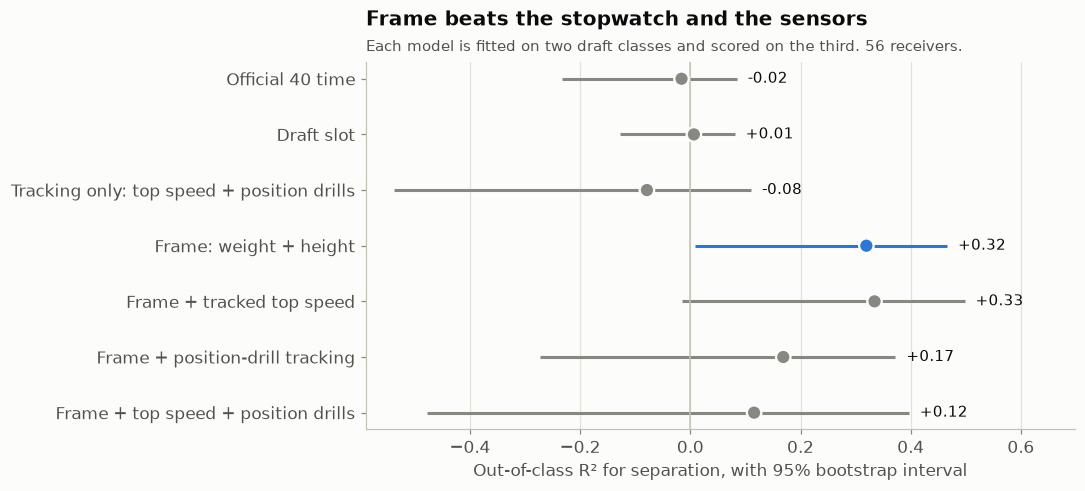

In [5]:
wr_tracking = combine_tracking.filter(pl.col("drill_type") == "SKILL_DRILLS_WR")
drill_table = drill_reps(wr_tracking).to_pandas()
print(f"Receiver position-drill reps: {len(drill_table):,} across {drill_table['drill_name'].nunique()} drills and {drill_table['nfl_id'].nunique()} prospects")
for metric in DRILL_METRICS:
    r = split_half_reliability(drill_table, f"{metric}_z", splits=200, seed=SEED)
    print(f"  split-half reliability of drill {metric} across a prospect's reps: r = {r:.2f} (Spearman-Brown {2 * r / (1 + r):.2f})")
drill_means = drill_table.groupby("nfl_id")[[f"{m}_z" for m in DRILL_METRICS]].mean().rename(columns=lambda c: "drill_" + c[:-2]).reset_index()
receivers = receivers.merge(drill_means, on="nfl_id", how="left")
DRILLS = "drill_brake + drill_accel + drill_speed"

common = receivers.dropna(subset=["forty", "top_speed", "drill_brake"]).reset_index(drop=True)
ladder = {
    "Official 40 time": "forty",
    "Draft slot": "log_pick",
    "Tracking only: top speed + position drills": f"top_speed + {DRILLS}",
    "Frame: weight + height": FRAME,
    "Frame + tracked top speed": f"{FRAME} + top_speed",
    "Frame + position-drill tracking": f"{FRAME} + {DRILLS}",
    "Frame + top speed + position drills": f"{FRAME} + top_speed + {DRILLS}",
}
rng = np.random.default_rng(SEED)
draws = rng.integers(0, len(common), (2000, len(common)))
rows = []
for label, features in ladder.items():
    predicted = leave_one_class_out(common, features, "separation_adj")
    boot = [r2_score(common["separation_adj"].to_numpy()[i], predicted[i]) for i in draws]
    rows.append({"model": label, "r2": r2_score(common["separation_adj"], predicted), "low": np.percentile(boot, 2.5), "high": np.percentile(boot, 97.5), "r": np.corrcoef(predicted, common["separation_adj"])[0, 1]})
ladder_table = pd.DataFrame(rows)
print(f"\nLeave-one-draft-class-out R2 for role-adjusted separation, same {len(common)} receivers in every row:")
print(ladder_table.round(3).to_string(index=False))
for metric in ["top_speed", "drill_brake", "drill_accel", "drill_speed"]:
    beyond = smf.ols(f"separation_adj ~ {FRAME} + {metric}", common).fit()
    print(f"  {metric} beyond frame: t = {beyond.tvalues[metric]:+.2f} (p = {beyond.pvalues[metric]:.2f}) | raw r with separation {common[metric].corr(common['separation_adj']):+.2f}")

role = leave_one_class_out(common, "top_speed", "vertical_share")
print(f"\nRole instead of openness: tracked top speed vs share of routes that are go, post or corner: in-sample r = {common['top_speed'].corr(common['vertical_share']):+.2f}, out-of-class R2 = {r2_score(common['vertical_share'], role):+.3f}")

fig, ax = plt.subplots(figsize=(10, 4.6))
order = ladder_table.iloc[::-1].reset_index(drop=True)
colors = [BLUE if m.startswith("Frame: ") else MUTED for m in order["model"]]
ax.hlines(order.index, order["low"], order["high"], color=colors, linewidth=2, zorder=2)
ax.scatter(order["r2"], order.index, s=90, color=colors, edgecolor=SURFACE, linewidth=1.5, zorder=3)
ax.axvline(0, color=AXIS, linewidth=1)
for i, row in order.iterrows():
    ax.text(row["high"] + 0.02, i, f"{row['r2']:+.2f}", va="center", fontsize=10, color=INK)
ax.set_yticks(order.index, order["model"])
ax.set_xlim(order["low"].min() - 0.05, order["high"].max() + 0.2)
ax.set_xlabel("Out-of-class R\u00b2 for separation, with 95% bootstrap interval")
ax.grid(axis="y", visible=False)
headline(ax, "Frame beats the stopwatch and the sensors", f"Each model is fitted on two draft classes and scored on the third. {len(common)} receivers.")
fig.tight_layout()
fig.savefig("fig2_out_of_class_ladder.png", dpi=160)
plt.show()

## 5. Where size costs the most

The same comparison at the level of single reps, one route type at a time: how many yards of separation go with ten more pounds of receiver, holding alignment, coverage type and season fixed. Standard errors are clustered by receiver.

Yards of separation per 10 lb heavier, by route (alignment, coverage type and season held fixed):
 route  mean_separation  reps  slope    se     p
SCREEN            6.656   923 -0.219 0.097 0.024
 CROSS            3.322  3686 -0.170 0.041 0.000
  FLAT            4.509   829 -0.101 0.088 0.250
 HITCH            3.072  4855 -0.087 0.025 0.000
    IN            2.949  3308 -0.083 0.022 0.000
    GO            2.596  5826 -0.082 0.023 0.000
  POST            2.989  3017 -0.069 0.020 0.000
CORNER            2.960  2413 -0.047 0.020 0.019
 SLANT            2.780  2053 -0.033 0.044 0.451
   OUT            3.023  2904 -0.029 0.026 0.268

Same slope by situation:
  all routes             -0.086 yd (se 0.016, p = 0.0000, 29,878 reps)
  against man coverage   -0.050 yd (se 0.018, p = 0.0047, 8,268 reps)


  against zone coverage  -0.100 yd (se 0.017, p = 0.0000, 21,597 reps)
  lined up in the slot   -0.062 yd (se 0.021, p = 0.0026, 10,486 reps)
  lined up wide          -0.095 yd (se 0.019, p = 0.0000, 18,438 reps)



Cushion at the snap per 10 lb heavier: -0.083 yd (p = 0.007, 28,341 reps)
Separation slope on those reps: -0.085 yd, and -0.072 yd with cushion held fixed (15% of the slope runs through cushion)


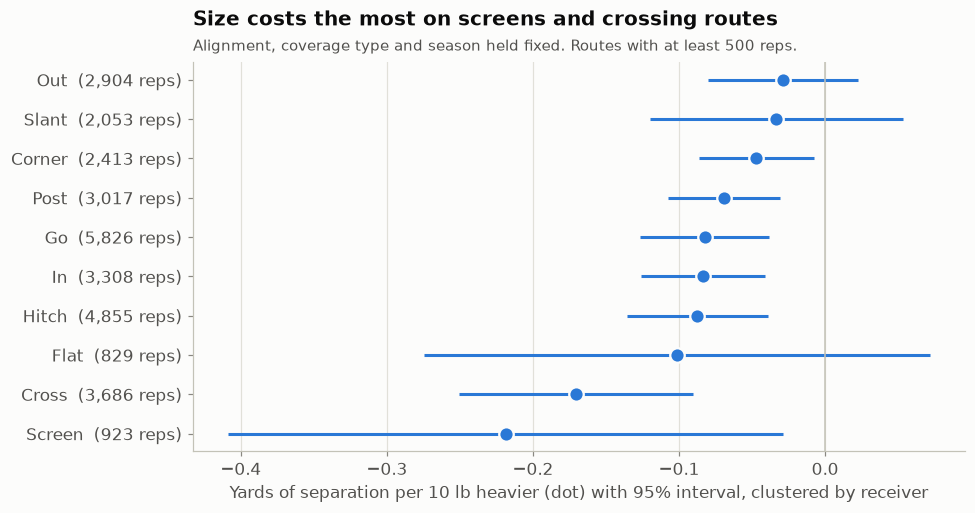

In [6]:
reps = cohort_routes.merge(receivers[["nfl_id", "combine_weight"]], on="nfl_id")
reps["per_10_lb"] = reps["combine_weight"] / 10
SITUATION = "C(lined_up_position) + C(team_coverage_man_zone) + C(season)"


def weight_slope(frame, controls):
    """Yards of separation per 10 lb of receiver weight, with standard errors clustered by receiver."""
    model = smf.ols(f"separation ~ per_10_lb + {controls}", frame).fit(cov_type="cluster", cov_kwds={"groups": frame["nfl_id"]})
    return {"reps": len(frame), "slope": model.params["per_10_lb"], "se": model.bse["per_10_lb"], "p": model.pvalues["per_10_lb"]}


by_route = pd.DataFrame(
    [{"route": route, "mean_separation": group["separation"].mean()} | weight_slope(group, SITUATION) for route, group in reps.groupby("route_ran") if len(group) >= 500]
).sort_values("slope")
print("Yards of separation per 10 lb heavier, by route (alignment, coverage type and season held fixed):")
print(by_route.round(3).to_string(index=False))
print("\nSame slope by situation:")
splits = {
    "all routes": reps,
    "against man coverage": reps[reps["team_coverage_man_zone"] == "MAN_COVERAGE"],
    "against zone coverage": reps[reps["team_coverage_man_zone"] == "ZONE_COVERAGE"],
    "lined up in the slot": reps[reps["lined_up_position"] == "SLOT_WR"],
    "lined up wide": reps[reps["lined_up_position"] == "WR"],
}
for label, group in splits.items():
    s = weight_slope(group, f"C(route_ran) + {SITUATION}")
    print(f"  {label:22s} {s['slope']:+.3f} yd (se {s['se']:.3f}, p = {s['p']:.4f}, {s['reps']:,} reps)")

with_cushion = reps.dropna(subset=["cushion"])
cushion = smf.ols(f"cushion ~ per_10_lb + C(route_ran) + {SITUATION}", with_cushion).fit(cov_type="cluster", cov_kwds={"groups": with_cushion["nfl_id"]})
before = weight_slope(with_cushion, f"C(route_ran) + {SITUATION}")
after = weight_slope(with_cushion, f"cushion + C(route_ran) + {SITUATION}")
print(f"\nCushion at the snap per 10 lb heavier: {cushion.params['per_10_lb']:+.3f} yd (p = {cushion.pvalues['per_10_lb']:.3f}, {len(with_cushion):,} reps)")
print(f"Separation slope on those reps: {before['slope']:+.3f} yd, and {after['slope']:+.3f} yd with cushion held fixed ({1 - after['slope'] / before['slope']:.0%} of the slope runs through cushion)")

fig, ax = plt.subplots(figsize=(9, 4.8))
y = np.arange(len(by_route))
ax.hlines(y, by_route["slope"] - 1.96 * by_route["se"], by_route["slope"] + 1.96 * by_route["se"], color=BLUE, linewidth=2, zorder=2)
ax.scatter(by_route["slope"], y, s=90, color=BLUE, edgecolor=SURFACE, linewidth=1.5, zorder=3)
ax.axvline(0, color=AXIS, linewidth=1)
ax.set_yticks(y, [f"{r.route.title()}  ({r.reps:,} reps)" for r in by_route.itertuples()])
ax.set_xlabel("Yards of separation per 10 lb heavier (dot) with 95% interval, clustered by receiver")
ax.grid(axis="y", visible=False)
headline(ax, "Size costs the most on screens and crossing routes", "Alignment, coverage type and season held fixed. Routes with at least 500 reps.")
fig.tight_layout()
fig.savefig("fig3_weight_slope_by_route.png", dpi=160)
plt.show()

## 6. Why: play speed

Game tracking covers each receiver from the snap to the throw on every route. Play speed here is his peak speed in that window, compared with the average for the same route, alignment, coverage type, season and time to throw. Time to throw has to be held fixed because a longer play gives any receiver more time to build speed.

Game tracking frames on the cohort's route plays: 6,692,236 (every tracked rookie on those plays)


Route reps tracked from snap to throw: 29,704 | median time to throw 2.7 s | mean peak speed before the throw 6.78 yd/s
Split-half reliability of play speed (route, alignment, coverage, season and time to throw held fixed): r = 0.86 (Spearman-Brown 0.92)


Peak speed before the throw per 10 lb heavier, same route and time to throw: -0.063 yd/s (se 0.012, p = 2.8e-07)
Play speed vs combine_weight: r = -0.46 (p = 1.5e-04, n = 62)
Play speed vs combine_height: r = -0.26 (p = 4.5e-02, n = 62)
Play speed vs separation_adj: r = +0.51 (p = 2.2e-05, n = 62)
Play speed vs Combine tracked top speed: r = +0.50 | vs official 40 time: r = -0.41 (n = 56)

Does play speed carry the frame effect? Role-adjusted separation, in sample:
  frame                R2 = 0.37 | t: combine_weight -2.85, combine_height -1.06
  play speed           R2 = 0.26 | t: play_speed_adj +4.61
  frame + play speed   R2 = 0.45 | t: combine_weight -1.43, combine_height -1.66, play_speed_adj +2.98

What predicts play speed in an unseen draft class (56 receivers with a timed and tracked 40):
  official 40 time           out-of-class R2 = -0.037 (r = +0.22)
  tracked top speed          out-of-class R2 = +0.150 (r = +0.40)
  frame                      out-of-class R2 = +0.083 (r = +

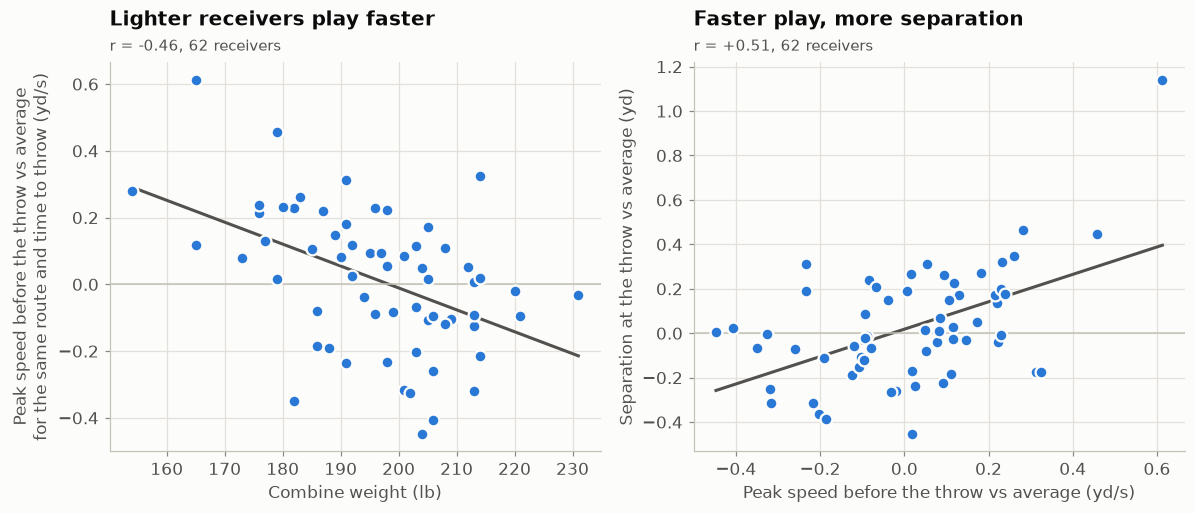

In [7]:
route_plays = pl.from_pandas(cohort_routes[["game_id", "play_id"]].drop_duplicates())
tracking = (
    pl.concat(
        [
            pl.scan_csv(DATA_DIR / f"game_tracking_{season}.csv", null_values=["NA", ""], schema_overrides={"event": pl.Utf8}).select(REP + ["time", "x", "y", "s", "event"])
            for season in SEASONS
        ]
    )
    .join(route_plays.lazy(), on=["game_id", "play_id"], how="semi")
    .with_columns(pl.col("time").str.to_datetime())
    .collect()
)
print(f"Game tracking frames on the cohort's route plays: {tracking.height:,} (every tracked rookie on those plays)")

speed = play_speed(tracking).to_pandas().merge(cohort_routes, on=REP)
speed["play_speed_adj"] = context_residual(speed, "peak_speed", f"{CONTEXT} + time_to_throw + I(time_to_throw ** 2)")
receivers = receivers.merge(speed.groupby("nfl_id", as_index=False).agg(play_speed=("peak_speed", "mean"), play_speed_adj=("play_speed_adj", "mean")), on="nfl_id")
print(f"Route reps tracked from snap to throw: {len(speed):,} | median time to throw {speed['time_to_throw'].median():.1f} s | mean peak speed before the throw {speed['peak_speed'].mean():.2f} yd/s")
r = split_half_reliability(speed, "play_speed_adj", splits=200, seed=SEED)
print(f"Split-half reliability of play speed (route, alignment, coverage, season and time to throw held fixed): r = {r:.2f} (Spearman-Brown {2 * r / (1 + r):.2f})")

speed["per_10_lb"] = speed.merge(receivers[["nfl_id", "combine_weight"]], on="nfl_id")["combine_weight"].to_numpy() / 10
rep_fit = smf.ols(f"peak_speed ~ per_10_lb + {CONTEXT} + time_to_throw + I(time_to_throw ** 2)", speed).fit(cov_type="cluster", cov_kwds={"groups": speed["nfl_id"]})
print(f"Peak speed before the throw per 10 lb heavier, same route and time to throw: {rep_fit.params['per_10_lb']:+.3f} yd/s (se {rep_fit.bse['per_10_lb']:.3f}, p = {rep_fit.pvalues['per_10_lb']:.1e})")
for column in ["combine_weight", "combine_height", "separation_adj"]:
    r, p = stats.pearsonr(receivers[column], receivers["play_speed_adj"])
    print(f"Play speed vs {column}: r = {r:+.2f} (p = {p:.1e}, n = {len(receivers)})")
timed = receivers.dropna(subset=["top_speed", "forty"]).reset_index(drop=True)
print(f"Play speed vs Combine tracked top speed: r = {timed['top_speed'].corr(timed['play_speed_adj']):+.2f} | vs official 40 time: r = {timed['forty'].corr(timed['play_speed_adj']):+.2f} (n = {len(timed)})")

print("\nDoes play speed carry the frame effect? Role-adjusted separation, in sample:")
for label, features in {"frame": FRAME, "play speed": "play_speed_adj", "frame + play speed": f"{FRAME} + play_speed_adj"}.items():
    model = smf.ols(f"separation_adj ~ {features}", receivers).fit()
    print(f"  {label:20s} R2 = {model.rsquared:.2f} | t: " + ", ".join(f"{k} {v:+.2f}" for k, v in model.tvalues.items() if k != "Intercept"))
print(f"\nWhat predicts play speed in an unseen draft class ({len(timed)} receivers with a timed and tracked 40):")
for label, features in {"official 40 time": "forty", "tracked top speed": "top_speed", "frame": FRAME, "frame + official 40 time": f"{FRAME} + forty", "frame + tracked top speed": f"{FRAME} + top_speed"}.items():
    predicted = leave_one_class_out(timed, features, "play_speed_adj")
    print(f"  {label:26s} out-of-class R2 = {r2_score(timed['play_speed_adj'], predicted):+.3f} (r = {np.corrcoef(predicted, timed['play_speed_adj'])[0, 1]:+.2f})")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), sharey=False)
panels = [
    (axes[0], "combine_weight", "play_speed_adj", "Combine weight (lb)", "Peak speed before the throw vs average\nfor the same route and time to throw (yd/s)", "Lighter receivers play faster"),
    (axes[1], "play_speed_adj", "separation_adj", "Peak speed before the throw vs average (yd/s)", "Separation at the throw vs average (yd)", "Faster play, more separation"),
]
for ax, x, y, xlabel, ylabel, title in panels:
    ax.scatter(receivers[x], receivers[y], s=60, color=BLUE, edgecolor=SURFACE, linewidth=1.5, zorder=3)
    slope, intercept = np.polyfit(receivers[x], receivers[y], 1)
    grid = np.linspace(receivers[x].min(), receivers[x].max(), 50)
    ax.plot(grid, intercept + slope * grid, color=INK_SECONDARY, linewidth=2, zorder=2)
    ax.axhline(0, color=AXIS, linewidth=1)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    headline(ax, title, f"r = {receivers[x].corr(receivers[y]):+.2f}, {len(receivers)} receivers")
fig.tight_layout()
fig.savefig("fig4_play_speed.png", dpi=160)
plt.show()

## 7. In season: frame against a receiver's own tape

A team watching a rookie has two sources for how open he will get: what the scale and tape measure said in Indianapolis, and how open he has been so far. This cell orders each receiver's routes through his career, takes the first N as the tape seen so far, and forecasts his separation on all later routes from each source.

After 25 routes (60 receivers): his own separation so far correlates r = +0.31 with his later separation
After 50 routes (56 receivers): his own separation so far correlates r = +0.42 with his later separation
After 100 routes (44 receivers): his own separation so far correlates r = +0.36 with his later separation
After 200 routes (34 receivers): his own separation so far correlates r = +0.41 with his later separation
Forecasting a receiver's role-adjusted separation on all later routes (at least 100) after seeing his first N, leave-one-draft-class-out R2:
forecast               His own separation so far  Frame only  Frame + his own separation so far
routes_seen receivers                                                                          
25          60                              0.02        0.32                               0.24
50          56                              0.15        0.36                               0.42
100         44                              0.09     

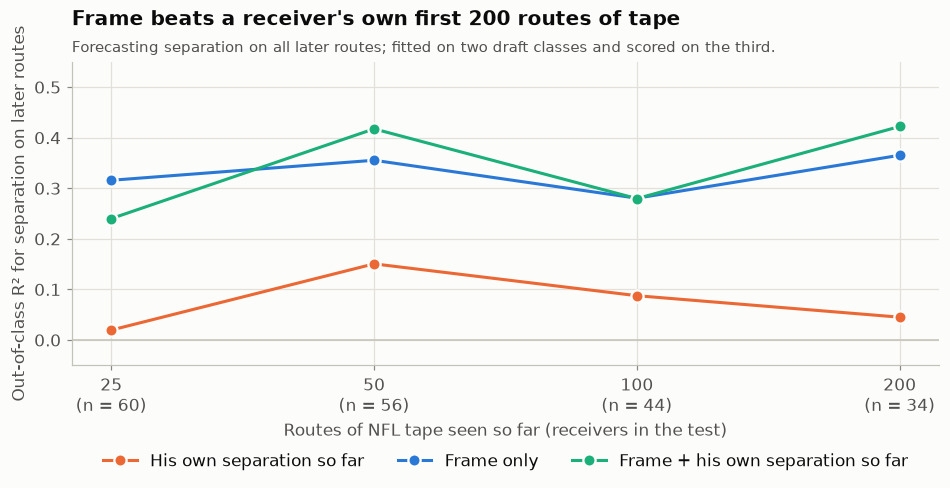

In [8]:
ordered = cohort_routes.sort_values(REP).copy()
ordered["nth"] = ordered.groupby("nfl_id").cumcount()
sources = {"His own separation so far": "tape", "Frame only": FRAME, "Frame + his own separation so far": f"{FRAME} + tape"}
rows = []
for seen in (25, 50, 100, 200):
    tape = ordered[ordered["nth"] < seen].groupby("nfl_id")["separation_adj"].mean().rename("tape")
    later = ordered[ordered["nth"] >= seen].groupby("nfl_id")["separation_adj"].agg(later="mean", later_routes="size")
    table = receivers[["nfl_id", "draft_year", "combine_weight", "combine_height"]].merge(tape, on="nfl_id").merge(later[later["later_routes"] >= MIN_ROUTES], on="nfl_id")
    for label, features in sources.items():
        rows.append({"routes_seen": seen, "forecast": label, "receivers": len(table), "out_of_class_r2": r2_score(table["later"], leave_one_class_out(table, features, "later"))})
    print(f"After {seen} routes ({len(table)} receivers): his own separation so far correlates r = {table['tape'].corr(table['later']):+.2f} with his later separation")
forecast = pd.DataFrame(rows)
print(f"Forecasting a receiver's role-adjusted separation on all later routes (at least {MIN_ROUTES}) after seeing his first N, leave-one-draft-class-out R2:")
print(forecast.pivot(index=["routes_seen", "receivers"], columns="forecast", values="out_of_class_r2")[list(sources)].round(2).to_string())

seasons = cohort_routes.groupby(["nfl_id", "season"], as_index=False).agg(routes=("separation", "size"), separation_adj=("separation_adj", "mean"))
seasons = seasons[seasons["routes"] >= MIN_ROUTES].merge(receivers[["nfl_id", "expected"]], on="nfl_id")
seasons["beyond_frame"] = seasons["separation_adj"] - seasons["expected"]
pairs = seasons.merge(seasons.assign(season=seasons["season"] - 1), on=["nfl_id", "season"], suffixes=("", "_next"))
print(f"\nConsecutive seasons with at least {MIN_ROUTES} routes each: {len(pairs)} pairs from {pairs['nfl_id'].nunique()} receivers")
for column, label in [("separation_adj", "role-adjusted separation"), ("beyond_frame", "separation beyond the frame expectation")]:
    r, p = stats.pearsonr(pairs[column], pairs[f"{column}_next"])
    print(f"  season-to-season r of {label}: {r:+.2f} (p = {p:.2f})")
r, p = stats.pearsonr(pairs["expected"], pairs["separation_adj_next"])
print(f"  frame expectation vs next season's separation: r = {r:+.2f} (p = {p:.1e})")

fig, ax = plt.subplots(figsize=(9, 4.8))
for (label, _), color in zip(sources.items(), [ORANGE, BLUE, AQUA]):
    line = forecast[forecast["forecast"] == label]
    ax.plot(line["routes_seen"], line["out_of_class_r2"], color=color, linewidth=2, marker="o", markersize=8, markeredgecolor=SURFACE, markeredgewidth=1.5, label=label, zorder=3)
ax.axhline(0, color=AXIS, linewidth=1)
ax.set_xscale("log")
ax.set_xticks([25, 50, 100, 200], [f"{n}\n(n = {forecast[forecast['routes_seen'] == n]['receivers'].iloc[0]})" for n in (25, 50, 100, 200)])
ax.minorticks_off()
ax.set_xlabel("Routes of NFL tape seen so far (receivers in the test)")
ax.set_ylabel("Out-of-class R\u00b2 for separation on later routes")
ax.set_ylim(-0.05, 0.55)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.24), ncol=3)
headline(ax, "Frame beats a receiver's own first 200 routes of tape", "Forecasting separation on all later routes; fitted on two draft classes and scored on the third.")
fig.tight_layout()
fig.savefig("fig5_frame_vs_tape.png", dpi=160)
plt.show()

## 8. Two typical reps

The tracking follows only the rookie cohort, so most plays show a receiver with no defender. On some plays a second tracked rookie is the nearest defender, which can be confirmed exactly: his tracked distance at the throw equals the recorded separation. The animation shows one such crossing route for a lighter and a heavier receiver. Each rep is the one closest to its weight group's median separation among reps thrown in a typical time, so the pair is typical by construction and is an illustration, not evidence.

Cross routes where a second tracked rookie is the recorded nearest defender at the throw: 465 reps by 59 receivers
  190 lb or lighter: 159 reps, median separation 3.20 yd | shown: Tre Tucker (182 lb) vs Nohl Williams, 3.26 yd at the throw after 2.8 s
  210 lb or heavier: 83 reps, median separation 2.14 yd | shown: Keon Coleman (213 lb) vs Marcellas Dial, 2.14 yd at the throw after 2.7 s


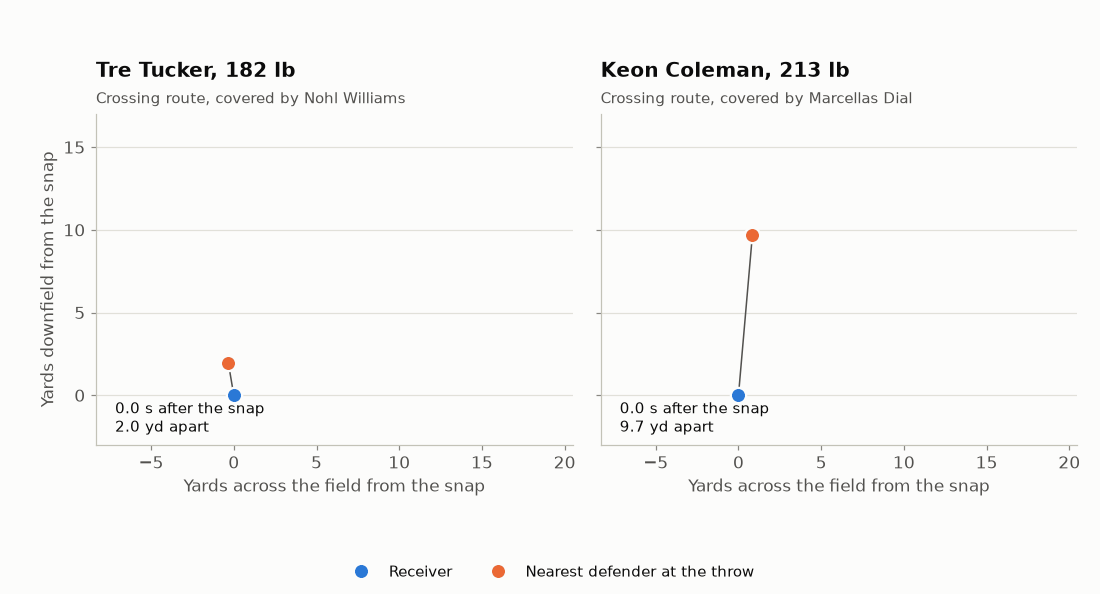

In [9]:
from IPython.display import Image

ROUTE = "CROSS"
LIGHT_MAX, HEAVY_MIN = 190, 210
MATCH_TOLERANCE = 0.15
TYPICAL_TIME_TO_THROW = (2.5, 3.0)
PLAY = ["game_id", "play_id"]

at_throw = tracking.filter(pl.col("event") == "pass_forward").select(REP + ["x", "y"]).unique(REP)
defenders = plays.filter(pl.col("team_abbr") != pl.col("possession_team")).select(PLAY + [pl.col("nfl_id").alias("defender_id")])
candidates = (
    pl.from_pandas(speed.loc[speed["route_ran"] == ROUTE, REP + ["separation", "time_to_throw"]])
    .join(at_throw, on=REP)
    .join(defenders, on=PLAY)
    .join(at_throw.rename({"nfl_id": "defender_id", "x": "defender_x", "y": "defender_y"}), on=PLAY + ["defender_id"])
    .filter((((pl.col("x") - pl.col("defender_x")) ** 2 + (pl.col("y") - pl.col("defender_y")) ** 2).sqrt() - pl.col("separation")).abs() <= MATCH_TOLERANCE)
    .sort(REP)
    .to_pandas()
    .merge(receivers[["nfl_id", "display_name", "combine_weight"]], on="nfl_id")
    .merge(players.select(["nfl_id", "display_name"]).rename({"nfl_id": "defender_id", "display_name": "defender_name"}).to_pandas(), on="defender_id")
    .merge(plays.select(REP + ["play_direction"]).to_pandas(), on=REP)
)
print(f"{ROUTE.title()} routes where a second tracked rookie is the recorded nearest defender at the throw: {len(candidates)} reps by {candidates['nfl_id'].nunique()} receivers")

picks = []
for label, group in [(f"{LIGHT_MAX} lb or lighter", candidates[candidates["combine_weight"] <= LIGHT_MAX]), (f"{HEAVY_MIN} lb or heavier", candidates[candidates["combine_weight"] >= HEAVY_MIN])]:
    typical = group[group["time_to_throw"].between(*TYPICAL_TIME_TO_THROW)]
    pick = typical.loc[(typical["separation"] - group["separation"].median()).abs().idxmin()]
    picks.append(pick)
    print(f"  {label}: {len(group)} reps, median separation {group['separation'].median():.2f} yd | shown: {pick['display_name']} ({pick['combine_weight']:.0f} lb) vs {pick['defender_name']}, {pick['separation']:.2f} yd at the throw after {pick['time_to_throw']:.1f} s")

paths = []
for pick in picks:
    frames = tracking.filter((pl.col("game_id") == pick["game_id"]) & (pl.col("play_id") == pick["play_id"]) & pl.col("nfl_id").is_in([pick["nfl_id"], pick["defender_id"]])).sort("time").to_pandas()
    receiver = frames[frames["nfl_id"] == pick["nfl_id"]]
    snap = receiver.loc[receiver["event"] == "ball_snap", "time"].iloc[0]
    throw = receiver.loc[receiver["event"] == "pass_forward", "time"].iloc[0]
    origin = receiver.loc[receiver["time"] == snap, ["x", "y"]].iloc[0]
    frames = frames[frames["time"].between(snap, throw)]
    sign = 1 if pick["play_direction"] == "right" else -1
    frames = frames.assign(downfield=(frames["x"] - origin["x"]) * sign, lateral=(frames["y"] - origin["y"]) * sign, seconds=(frames["time"] - snap).dt.total_seconds())
    receiver = frames[frames["nfl_id"] == pick["nfl_id"]].reset_index(drop=True)
    defender = frames[frames["nfl_id"] == pick["defender_id"]].reset_index(drop=True)
    mirror = np.sign(receiver["lateral"].iloc[-1])
    paths.append((receiver.assign(lateral=receiver["lateral"] * mirror), defender.assign(lateral=defender["lateral"] * mirror)))

everything = pd.concat([part for pair in paths for part in pair])
fig, axes = plt.subplots(1, 2, figsize=(10, 5.4), sharex=True, sharey=True)
artists = []
for ax, pick, (receiver, defender) in zip(axes, picks, paths):
    ax.set_xlim(everything["lateral"].min() - 8, everything["lateral"].max() + 8)
    ax.set_ylim(everything["downfield"].min() - 3, everything["downfield"].max() + 3)
    ax.set_aspect("equal")
    ax.grid(axis="x", visible=False)
    ax.yaxis.set_major_locator(plt.MultipleLocator(5))
    ax.set_xlabel("Yards across the field from the snap")
    headline(ax, f"{pick['display_name']}, {pick['combine_weight']:.0f} lb", f"Crossing route, covered by {pick['defender_name']}")
    artists.append(
        {
            "receiver_trail": ax.plot([], [], color=BLUE, linewidth=2)[0],
            "defender_trail": ax.plot([], [], color=ORANGE, linewidth=2)[0],
            "gap": ax.plot([], [], color=INK_SECONDARY, linewidth=1)[0],
            "receiver": ax.plot([], [], "o", color=BLUE, markersize=10, markeredgecolor=SURFACE, markeredgewidth=1.5, label="Receiver")[0],
            "defender": ax.plot([], [], "o", color=ORANGE, markersize=10, markeredgecolor=SURFACE, markeredgewidth=1.5, label="Nearest defender at the throw")[0],
            "readout": ax.text(0.04, 0.04, "", transform=ax.transAxes, fontsize=10, color=INK),
        }
    )
axes[0].set_ylabel("Yards downfield from the snap")
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=2, fontsize=10)
fig.tight_layout(rect=(0.02, 0.06, 1, 1))
HOLD = 15
steps = max(len(receiver) for receiver, _ in paths)


def draw(step):
    """Advance both reps to the same time since the snap, holding each at its throw."""
    for parts, (receiver, defender) in zip(artists, paths):
        i = min(step, len(receiver) - 1, len(defender) - 1)
        parts["receiver_trail"].set_data(receiver["lateral"][: i + 1], receiver["downfield"][: i + 1])
        parts["defender_trail"].set_data(defender["lateral"][: i + 1], defender["downfield"][: i + 1])
        parts["receiver"].set_data([receiver["lateral"][i]], [receiver["downfield"][i]])
        parts["defender"].set_data([defender["lateral"][i]], [defender["downfield"][i]])
        parts["gap"].set_data([receiver["lateral"][i], defender["lateral"][i]], [receiver["downfield"][i], defender["downfield"][i]])
        apart = np.hypot(receiver["lateral"][i] - defender["lateral"][i], receiver["downfield"][i] - defender["downfield"][i])
        parts["readout"].set_text(f"{receiver['seconds'][i]:.1f} s after the snap\n{apart:.1f} yd apart")
    return [a for parts in artists for a in parts.values()]


animation.FuncAnimation(fig, draw, frames=steps + HOLD, interval=100).save("fig6_crossing_route_reps.gif", writer=animation.PillowWriter(fps=10))
plt.close(fig)
Image(filename="fig6_crossing_route_reps.gif")

## 9. The same pattern in the trenches

Two short checks outside the receiver room. For defensive linemen, weight is set against the hoop drill as a predictor of NFL get-off time. For offensive linemen, the question is whether anything measured at the Combine relates to pressure probability allowed.

In [10]:
rushers = (
    plays.filter(pl.col("player_get_off").is_not_null())
    .group_by("nfl_id")
    .agg(pl.col("player_get_off").mean().alias("get_off"), pl.len().alias("rushes"))
    .filter(pl.col("rushes") >= 30)
)
hoop = (
    combine_tracking.filter((pl.col("entity_type") == "PLAYER") & pl.col("drill_name").str.contains("HOOP"))
    .group_by("nfl_id")
    .agg(pl.col("s").max().alias("hoop_speed"))
)
rushers = rushers.join(hoop, on="nfl_id").join(combine.select(["nfl_id", "combine_weight"]), on="nfl_id").to_pandas()
both = smf.ols("get_off ~ hoop_speed + combine_weight", rushers).fit()
print(f"Defensive linemen with at least 30 regular-season rushes and a tracked hoop drill: {len(rushers)}")
print(f"  NFL get-off time vs Combine weight: r = {rushers['combine_weight'].corr(rushers['get_off']):+.2f} | vs hoop-drill peak speed: r = {rushers['hoop_speed'].corr(rushers['get_off']):+.2f}")
print(f"  both together: R2 = {both.rsquared:.2f}, weight p = {both.pvalues['combine_weight']:.1e}, hoop speed p = {both.pvalues['hoop_speed']:.2f}")

blocks = (
    plays.filter(pl.col("nfl_position").is_in(["T", "G", "C"]) & pl.col("peak_pressure_probability_allowed").is_not_null())
    .select(["nfl_id", "nfl_position", pl.col("peak_pressure_probability_allowed").alias("pressure_probability")])
    .to_pandas()
)
blockers = blocks.groupby(["nfl_id", "nfl_position"], as_index=False).agg(snaps=("pressure_probability", "size"), pressure_probability=("pressure_probability", "mean")).query("snaps >= 200")
r = split_half_reliability(blocks[blocks["nfl_id"].isin(blockers["nfl_id"])], "pressure_probability", splits=200, seed=SEED)
line_drills = drill_reps(combine_tracking.filter(pl.col("drill_type") == "SKILL_DRILLS_OL")).to_pandas()
blockers = blockers.merge(line_drills.groupby("nfl_id")[[f"{m}_z" for m in DRILL_METRICS]].mean().reset_index(), on="nfl_id").merge(prospects, on="nfl_id")
print(f"\nOffensive linemen with at least 200 regular-season pass-protection snaps: {len(blockers)}")
print(f"  split-half reliability of pressure probability allowed: r = {r:.2f} (Spearman-Brown {2 * r / (1 + r):.2f})")
for column, label in [("combine_weight", "Combine weight"), ("log_pick", "draft slot"), ("brake_z", "position-drill braking"), ("accel_z", "position-drill acceleration"), ("speed_z", "position-drill speed")]:
    corr, p = stats.pearsonr(blockers[column], blockers["pressure_probability"])
    print(f"  pressure probability allowed vs {label}: r = {corr:+.2f} (p = {p:.2f})")
for metric in DRILL_METRICS:
    r = split_half_reliability(line_drills, f"{metric}_z", splits=200, seed=SEED)
    print(f"  split-half reliability of line-drill {metric} across a prospect's reps: r = {r:.2f}")

Defensive linemen with at least 30 regular-season rushes and a tracked hoop drill: 78
  NFL get-off time vs Combine weight: r = +0.71 | vs hoop-drill peak speed: r = -0.53
  both together: R2 = 0.52, weight p = 4.3e-08, hoop speed p = 0.24



Offensive linemen with at least 200 regular-season pass-protection snaps: 58
  split-half reliability of pressure probability allowed: r = 0.84 (Spearman-Brown 0.92)
  pressure probability allowed vs Combine weight: r = +0.11 (p = 0.42)
  pressure probability allowed vs draft slot: r = -0.16 (p = 0.24)
  pressure probability allowed vs position-drill braking: r = -0.01 (p = 0.92)
  pressure probability allowed vs position-drill acceleration: r = +0.08 (p = 0.57)
  pressure probability allowed vs position-drill speed: r = -0.01 (p = 0.95)
  split-half reliability of line-drill brake across a prospect's reps: r = -0.00
  split-half reliability of line-drill accel across a prospect's reps: r = 0.20


  split-half reliability of line-drill speed across a prospect's reps: r = 0.58


## 10. Limits

- The cohort is 62 receivers from three draft classes. Intervals are wide, and leave-one-draft-class-out is the only test on players the model has not seen.
- Only rostered rookies who ran routes are in the data. Prospects who never played are missing, which narrows the range of every Combine measure.
- Separation is not production. A receiver can win with the catch point, with yards after the catch, or by drawing coverage.
- Role adjustment uses the route, alignment and coverage labels in the play table. It cannot see route depth, leverage or the quality of the defender.
- Frame and play speed are correlated traits measured on the same players. The play-speed result describes a pathway; it does not isolate a cause.

Data: NFL Big Data Bowl 2027, Michael Lopez, Ally Blake, Tom Bliss, Addison Howard and Paul Mooney, Kaggle 2026. No competition rows are exported by this notebook.